## Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

os.makedirs("figures", exist_ok=True)
W = 3.4                                              # APS single-column width in inches

plt.rcParams.update({                                # sizes only: the font itself stays the matplotlib default
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "lines.linewidth": 1.0,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "figure.dpi": 150, "savefig.dpi": 600, "pdf.fonttype": 42,
})
SQ3 = np.sqrt(3.0)

**Model functions** (the same definitions as in the analysis notebook).

In [2]:
a1 = np.array([1.0, 0.0]); a2 = np.array([0.5, SQ3/2]); a3 = a2 - a1       # nearest-neighbour vectors
RMAT = np.array([2*a1, 2*a2])                                              # primitive vectors
B1, B2 = 2*np.pi*np.linalg.inv(RMAT).T                                     # reciprocal vectors
CELL_AREA = abs(np.linalg.det(RMAT)); BZ_AREA = abs(np.linalg.det(np.array([B1, B2])))
K_POINT = (B1 + 2*B2)/3                                                    # corner of the hexagonal zone

def hamiltonian(kx, ky, t, lam, spin=+1):
    kx, ky = np.broadcast_arrays(np.asarray(kx, float), np.asarray(ky, float))
    k1 = kx*a1[0] + ky*a1[1]; k2 = kx*a2[0] + ky*a2[1]; k3 = kx*a3[0] + ky*a3[1]
    a = -t*np.cos(k1) + spin*1j*lam*np.cos(k2 + k3)
    b = -t*np.cos(k2) - spin*1j*lam*np.cos(k3 - k1)
    c = -t*np.cos(k3) + spin*1j*lam*np.cos(k1 + k2)
    h = np.zeros(kx.shape + (3, 3), dtype=complex)
    h[..., 0, 1], h[..., 0, 2], h[..., 1, 2] = a, b, c
    h[..., 1, 0], h[..., 2, 0], h[..., 2, 1] = a.conj(), b.conj(), c.conj()
    return h

def bands(kx, ky, t, lam, spin=+1):                  # E_n = 2 * eigenvalues of h, ascending
    return 2*np.linalg.eigvalsh(hamiltonian(kx, ky, t, lam, spin))

def bz_grid(N):                                      # (N+1)x(N+1) points on the cell spanned by b1, b2
    u = np.linspace(0.0, 1.0, N + 1); U1, U2 = np.meshgrid(u, u, indexing="ij")
    return U1*B1[0] + U2*B2[0], U1*B1[1] + U2*B2[1]

def k_path(labels=("Γ", "M", "K", "Γ"), n_per_segment=200):
    hsp = {"Γ": np.zeros(2), "M": B2/2, "K": K_POINT}
    pts = [hsp[l] for l in labels]; kk, xx, ticks, x0 = [], [], [0.0], 0.0
    for p, q in zip(pts[:-1], pts[1:]):
        s = np.linspace(0, 1, n_per_segment, endpoint=False)
        kk.append(p + s[:, None]*(q - p)); xx.append(x0 + s*np.linalg.norm(q - p))
        x0 += np.linalg.norm(q - p); ticks.append(x0)
    kk.append(pts[-1][None, :]); xx.append(np.array([x0]))
    return np.vstack(kk), np.concatenate(xx), np.array(ticks), list(labels)

def berry_curvature_grid(t, lam, N=200, spin=+1):
    """Fukui-Hatsugai curvature on an N x N grid over the zone: returns F_k (per unit k-area), F_q, Chern numbers."""
    KX, KY = bz_grid(N)
    w, v = np.linalg.eigh(hamiltonian(KX, KY, t, lam, spin))
    link = lambda x, y: np.sum(x.conj()*y, axis=-1)
    flux = np.empty((3, N, N))
    for n in range(3):
        p = v[..., n]
        flux[n] = np.angle(link(p[:-1, :-1], p[1:, :-1])*link(p[1:, :-1], p[1:, 1:]) *
                           link(p[1:, 1:], p[:-1, 1:])*link(p[:-1, 1:], p[:-1, :-1]))
    chern = np.round(flux.sum(axis=(1, 2))/(2*np.pi)).astype(int)
    dq = 2*np.pi/N
    return dict(KX=KX, KY=KY, chern=chern, F_k=flux/(BZ_AREA/N**2), F_q=flux/dq**2)

def curvature_spread(t, lam, N=200, spin=+1):
    """Spread <(Delta F^n)^2> with the zone area scaled to (2 pi)^2."""
    res = berry_curvature_grid(t, lam, N, spin); dq = 2*np.pi/N; C = res["chern"]
    return C, ((res["F_q"] - C[:, None, None]/(2*np.pi))**2).sum(axis=(1, 2))*dq**2/(4*np.pi**2)

## Figure 1: band structure for three values of $\lambda$ (spin up)

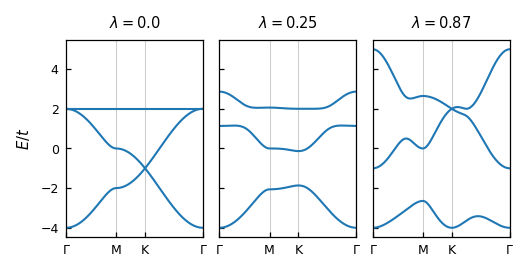

In [ ]:
t, spin = 1.0, +1
lams = (0.0, 0.25, SQ3/2)

kpts, xd, ticks, tlabels = k_path()
fig, axs = plt.subplots(1, 3, figsize=(W, 1.7), sharey=True)
for ax, lam in zip(axs, lams):
    E = bands(kpts[:, 0], kpts[:, 1], t, lam, spin)
    for x in ticks[1:-1]:
        ax.axvline(x, color="0.8", lw=0.5, zorder=0)
    for n in range(3):
        ax.plot(xd, E[:, n], color="tab:blue")
    ax.set_xticks(ticks); ax.set_xticklabels(tlabels)
    ax.set_xlim(xd[0], xd[-1])
    ax.set_title(rf"$\lambda = {np.round(lam, 2)}$")
axs[0].set_ylabel(r"$E/t$")
fig.subplots_adjust(left=0.115, right=0.985, bottom=0.12, top=0.89, wspace=0.12)
fig.savefig("figures/kagome_band_structure.pdf")
plt.show()

## Figure 2: Berry curvature for spin up and spin down

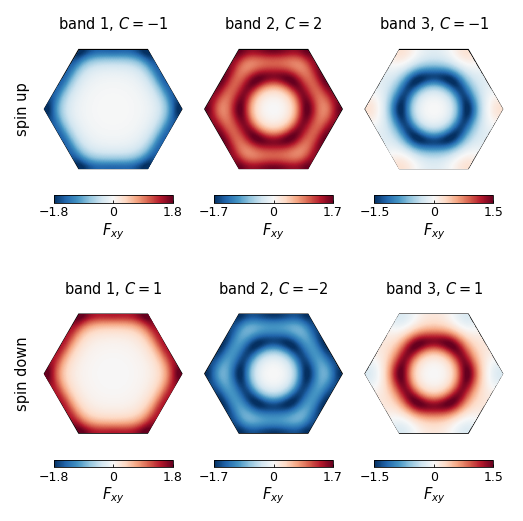

Chern numbers, spin up  : [-1  2 -1]
Chern numbers, spin down: [ 1 -2  1]


In [ ]:
t, lam = 1.0, 0.25
N = 500

R = np.linalg.norm(K_POINT)                                              # distance from Γ to a zone corner
hexa = np.array([[R*np.cos(a), R*np.sin(a)] for a in np.deg2rad(np.arange(0, 360, 60))])
tiles = [(m1, m2) for m1 in (-1, 0) for m2 in (-1, 0)]                   # copies of the cell that fill the hexagon
results = {s: berry_curvature_grid(t, lam, N, s) for s in (+1, -1)}
vmax = [np.percentile(np.abs(results[+1]["F_k"][n]), 99) for n in range(3)]   # same scale for both spins

fig, axs = plt.subplots(2, 3, figsize=(W, 3.5))
for r, s in enumerate((+1, -1)):
    res = results[s]
    for n in range(3):
        ax = axs[r, n]
        patch = Polygon(hexa, closed=True, fill=False, ec="k", lw=0.6, transform=ax.transData)
        ax.add_patch(patch)
        for (m1, m2) in tiles:
            off = m1*B1 + m2*B2
            mesh = ax.pcolormesh(res["KX"] + off[0], res["KY"] + off[1], res["F_k"][n], cmap="RdBu_r",
                                 vmin=-vmax[n], vmax=vmax[n], shading="flat", rasterized=True)
            mesh.set_clip_path(patch)
        ax.set_xlim(-1.08*R, 1.08*R); ax.set_ylim(-1.08*R, 1.08*R)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(rf"band {n+1}, $C = {res['chern'][n]}$", pad=3)
        if n == 0:
            ax.text(-0.06, 0.5, "spin " + (r"up" if s > 0 else r"down"), transform=ax.transAxes,
                    rotation=90, ha="right", va="center")
        # a horizontal colour bar under every panel (both rows share the same scale within a column)
        cax = ax.inset_axes([0.1, -0.13, 0.8, 0.05])
        cb = fig.colorbar(mesh, cax=cax, orientation="horizontal", ticks=[-vmax[n], 0, vmax[n]])
        cb.ax.set_xticklabels([f"\u2212{vmax[n]:.1f}", "0", f"{vmax[n]:.1f}"])
        cb.ax.tick_params(length=1.5, width=0.4, pad=1.5); cb.outline.set_linewidth(0.4)
        cb.set_label(r"$F_{xy}$", labelpad=1)
fig.subplots_adjust(left=0.07, right=0.99, bottom=0.10, top=0.94, wspace=0.08, hspace=0.50)
fig.savefig("figures/kagome_berry_curvature.pdf")
plt.show()
print("Chern numbers, spin up  :", results[+1]["chern"])
print("Chern numbers, spin down:", results[-1]["chern"])

## Figure 3: Berry curvature spread versus $\lambda/t$

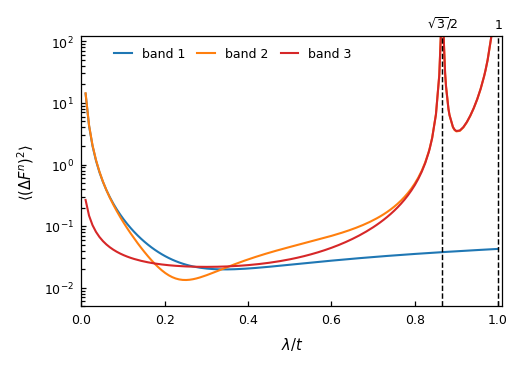

In [ ]:
t = 1.0
N = 500                                                            # grid per point; raise for smoother curves near the dashed lines
r_touch = (SQ3/2, 1.0)                                             # middle and top bands touch here (inside 0 < lambda/t <= 1)

offs = np.array([-.03, -.015, -.007, -.003, -.001, .001, .003, .007, .015, .03])
rr = np.unique(np.concatenate([np.linspace(0.01, 1.0, 120)] + [rc + offs for rc in r_touch]))
rr = rr[(rr > 0) & (rr <= 1.0)]
V = np.array([curvature_spread(t, x, N, +1)[1] for x in rr])               # shape (n_points, 3)

fig, ax = plt.subplots(figsize=(W, 2.4))
for n, col in enumerate(["tab:blue", "tab:orange", "tab:red"]):
    ax.plot(rr, V[:, n], color=col, label=f"band {n+1}")
for rc, lab in zip(r_touch, (r"$\sqrt{3}/2$", r"$1$")):
    ax.axvline(rc, color="k", ls="--", lw=0.7)
    ax.text(rc, 1.02, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=6)
ax.set_yscale("log"); ax.set_xlim(0, 1.01); ax.set_ylim(5e-3, 1.2e2)     # axis ends slightly past 1 so the dashed line at 1 is visible
ax.set_xlabel(r"$\lambda/t$"); ax.set_ylabel(r"$\langle(\Delta F^n)^2\rangle$")
ax.legend(loc="upper center", frameon=False, ncol=3, handlelength=1.4, columnspacing=1.0, bbox_to_anchor=(0.36, 1.0))
fig.subplots_adjust(left=0.15, right=0.975, bottom=0.17, top=0.92)
fig.savefig("figures/kagome_curvature_spread.pdf")
plt.show()

In [12]:
with open("kagome_spread.txt", "w") as file:
    for i in range(len(rr)):
        file.write(f"{rr[i]:.6f} {V[i, 0]:.6e} {V[i, 1]:.6e} {V[i, 2]:.6e}\n")